# Lab 2 – Predicting Diabetes Progression

In this lab I build models that predict how much a patient's diabetes progresses one year after their
first (baseline) visit. The idea is that a model like this could be used as a **screening tool**, so
doctors can spot patients who are at higher risk early.

The models I try are: polynomial regression on BMI only, multivariate polynomial regression, decision
trees, k-Nearest Neighbours (kNN) and logistic regression.

I compare them using **R²**, **Mean Absolute Error (MAE)** and **Mean Absolute Percentage Error (MAPE)**,
with a 75% / 10% / 15% train / validation / test split.

# Part 1 – Data
## 1. Get the data

I load the dataset with `load_diabetes` and use two of its options:
- `as_frame=True` so I get a pandas DataFrame with column names, instead of plain arrays.
- `scaled=False` so the features stay in their original units (for example BMI in kg/m² and age in
  years). By default sklearn scales every feature, which would make the BMI equation in Part 2 hard to
  read. With real units I can say things like "a BMI of 30 predicts ...".

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import datasets

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)

In [2]:
diabetes = datasets.load_diabetes(as_frame=True, scaled=False)
print(diabetes.DESCR[:1500])

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

The six blood test columns are called `s1` to `s6`, which isn't very readable. I used the dataset
description to rename them to what they actually measure.

In [3]:
column_names = {
    "s1": "tc",   # total serum cholesterol
    "s2": "ldl",  # low-density lipoproteins
    "s3": "hdl",  # high-density lipoproteins
    "s4": "tch",  # total cholesterol / HDL
    "s5": "ltg",  # log of serum triglycerides level
    "s6": "glu",  # blood sugar level
}
df = diabetes.frame.rename(columns=column_names)
df.head()

,age,sex,bmi,bp,tc,ldl,hdl,tch,ltg,glu,target
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.860,87.0,151.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.892,69.0,75.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.673,85.0,141.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.890,89.0,206.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.290,80.0,135.0


In [4]:
df.shape

(442, 11)

## 2. Frame the problem

**What am I predicting?** The `target` column. It's a number that measures how much the disease
progressed one year after baseline. A higher number means the disease got worse.

**What am I predicting it from?** 10 measurements taken at baseline for 442 patients: age, sex, BMI,
average blood pressure and six blood serum measurements.

**Why does it matter?** If doctors can see early which patients are likely to get worse, they can start
treatment or monitor those patients more closely before the disease progresses.

**What type of problem is it?**
- It's **supervised learning**, because every patient has a known target value to learn from.
- The target is a continuous number, so it's mainly a **regression** problem. That's what the
  polynomial models, regression trees and kNN regression do.
- But screening is really a yes/no question: *is this patient likely to progress more than most?* So
  I can also treat it as **binary classification**: **above-median progression** vs. not. That's how I
  use logistic regression in Part 3. The median (142, from the training set) is a statistical cut-off
  I chose to get balanced classes. It is **not** a clinical threshold.

**Ideas from the workshops that apply here**
- *Performance metrics (classification):* for a screening tool, the worst mistake is a
  **false negative**, where a high-risk patient isn't flagged and doesn't get follow-up. A false
  positive only means an extra check-up. So **recall** matters more to me than plain accuracy. A
  confusion matrix shows both kinds of mistakes, and I can lower the decision threshold to catch more
  high-risk patients (at the cost of more false alarms).
- *k-Nearest Neighbours:* kNN predicts by averaging the *k* most similar patients. "Similar" is
  measured by distance, so I have to **scale** the features first. Otherwise large-valued features like
  cholesterol would dominate. A small *k* follows the training data very closely (it can overfit), and
  a large *k* gives smoother predictions (it can underfit).
- *Logistic regression:* this gives the **probability** that a patient's progression will be above the
  median, using the sigmoid function. That's useful for screening because a doctor can choose the probability cut-off, and the
  coefficients show which features raise or lower the risk.

**How I measure the regression models**
- **R²**: how much of the variation in the target the model explains. 1 is perfect, 0 means it's no
  better than guessing the average, and it can even be negative.
- **MAE**: the average size of the error, in the same units as the target.
- **MAPE**: the average error as a percentage of the true value. It gets very large when the true value
  is small.

**Baseline:** the simplest possible model just predicts the training average every time (this is the
degree-0 model in Part 2). Any model I build has to beat that to be useful.

## 3. Exploratory Data Analysis
### 3.1 Structure and descriptive statistics

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   tc      442 non-null    float64
 5   ldl     442 non-null    float64
 6   hdl     442 non-null    float64
 7   tch     442 non-null    float64
 8   ltg     442 non-null    float64
 9   glu     442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB


In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,442.0,48.518,13.109,19.000,38.250,50.00,59.000,79.000
sex,442.0,1.468,0.500,1.000,1.000,1.00,2.000,2.000
bmi,442.0,26.376,4.418,18.000,23.200,25.70,29.275,42.200
bp,442.0,94.647,13.831,62.000,84.000,93.00,105.000,133.000
tc,442.0,189.140,34.608,97.000,164.250,186.00,209.750,301.000
ldl,442.0,115.439,30.413,41.600,96.050,113.00,134.500,242.400
hdl,442.0,49.788,12.934,22.000,40.250,48.00,57.750,99.000
tch,442.0,4.070,1.290,2.000,3.000,4.00,5.000,9.090
ltg,442.0,4.641,0.522,3.258,4.277,4.62,4.997,6.107
glu,442.0,91.260,11.496,58.000,83.250,91.00,98.000,124.000


In [7]:
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("\nSex counts:\n", df["sex"].value_counts())
print("\nSkewness:\n", df.skew().round(2))

Missing values: 0
Duplicate rows: 0

Sex counts:
 sex
1.0    235
2.0    207
Name: count, dtype: int64

Skewness:
 age      -0.23
sex       0.13
bmi       0.60
bp        0.29
tc        0.38
ldl       0.44
hdl       0.80
tch       0.74
ltg       0.29
glu       0.21
target    0.44
dtype: float64


### 3.2 Distributions (histograms)

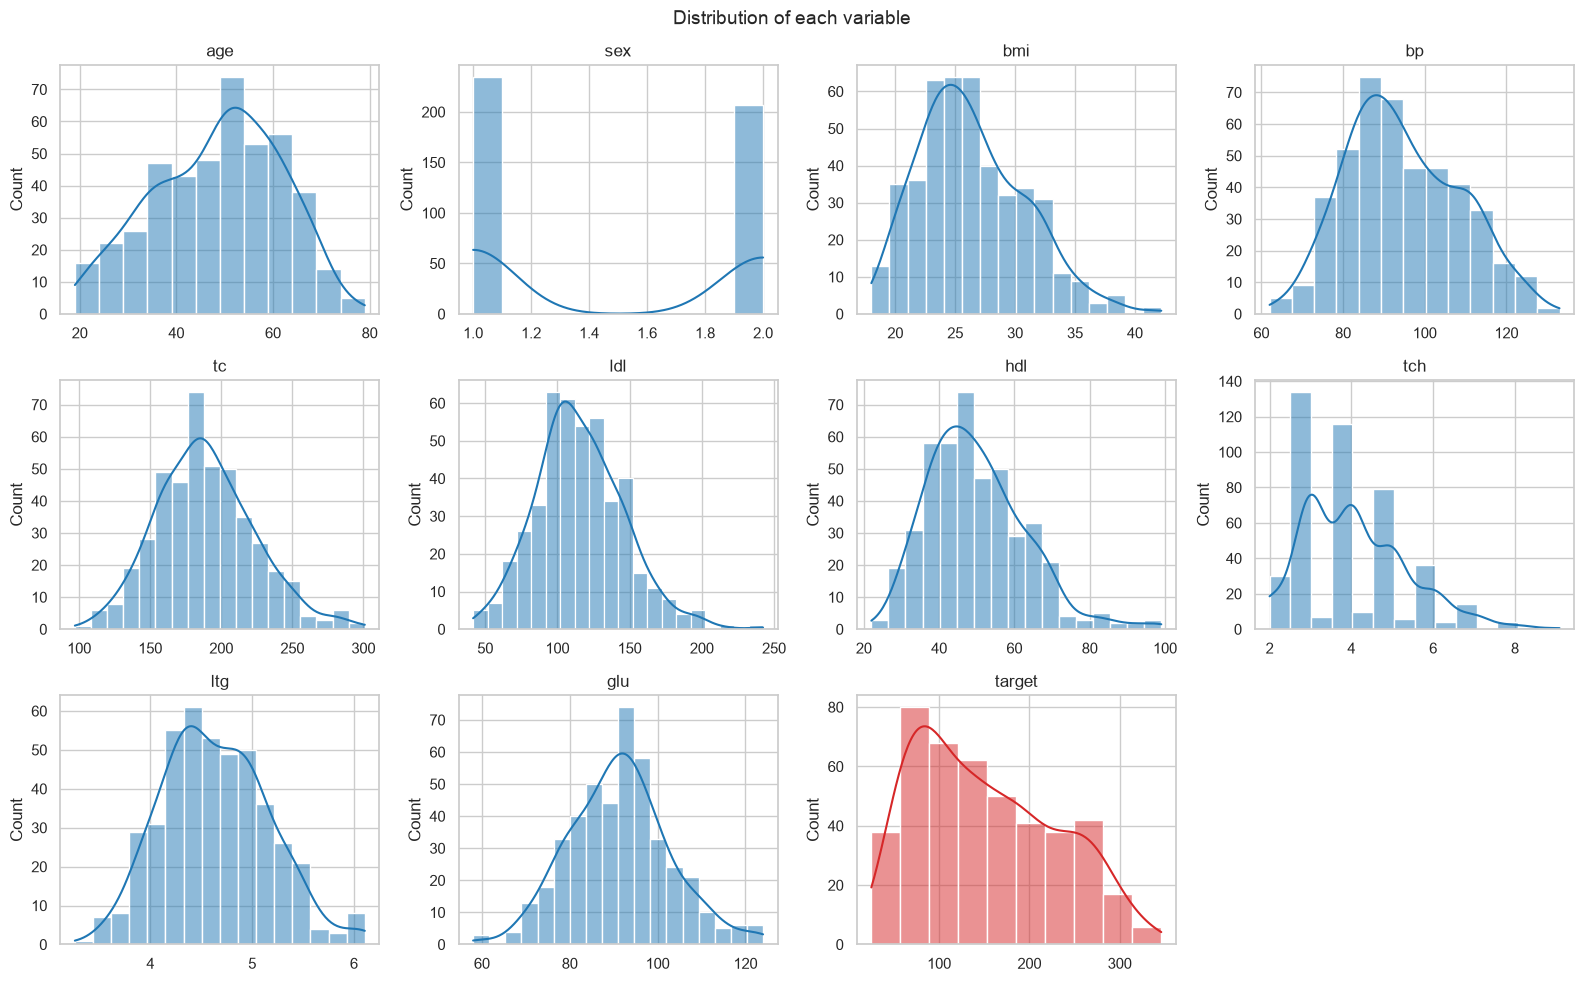

In [8]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flat, df.columns):
    sns.histplot(df[col], kde=True, ax=ax, color="tab:red" if col == "target" else "tab:blue")
    ax.set_title(col)
    ax.set_xlabel("")
axes.flat[-1].axis("off")
fig.suptitle("Distribution of each variable", fontsize=14)
fig.tight_layout()
plt.show()

### 3.3 Outliers (box plots, IQR rule)

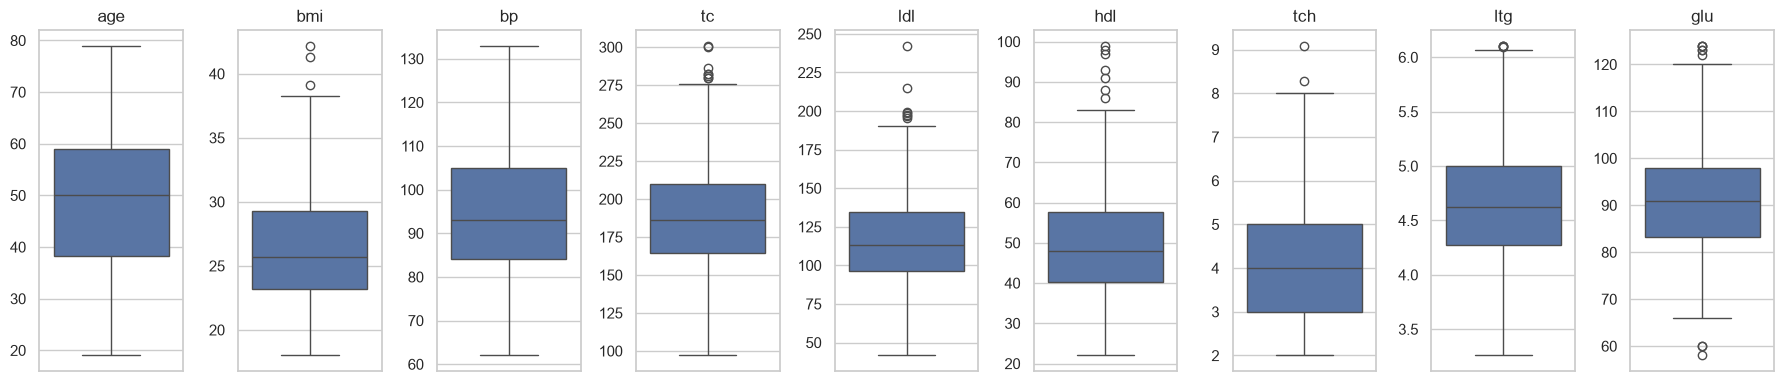

,age,bmi,bp,tc,ldl,hdl,tch,ltg,glu
IQR outliers,0,3,0,8,7,7,2,4,9


In [9]:
features = df.columns.drop(["target", "sex"])
fig, axes = plt.subplots(1, len(features), figsize=(18, 4))
for ax, col in zip(axes, features):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
    ax.set_ylabel("")
fig.tight_layout()
plt.show()

q1, q3 = df[features].quantile(0.25), df[features].quantile(0.75)
iqr = q3 - q1
outliers = ((df[features] < q1 - 1.5 * iqr) | (df[features] > q3 + 1.5 * iqr)).sum()
outliers.rename("IQR outliers").to_frame().T

### 3.4 Each feature vs. the target (scatter plots)

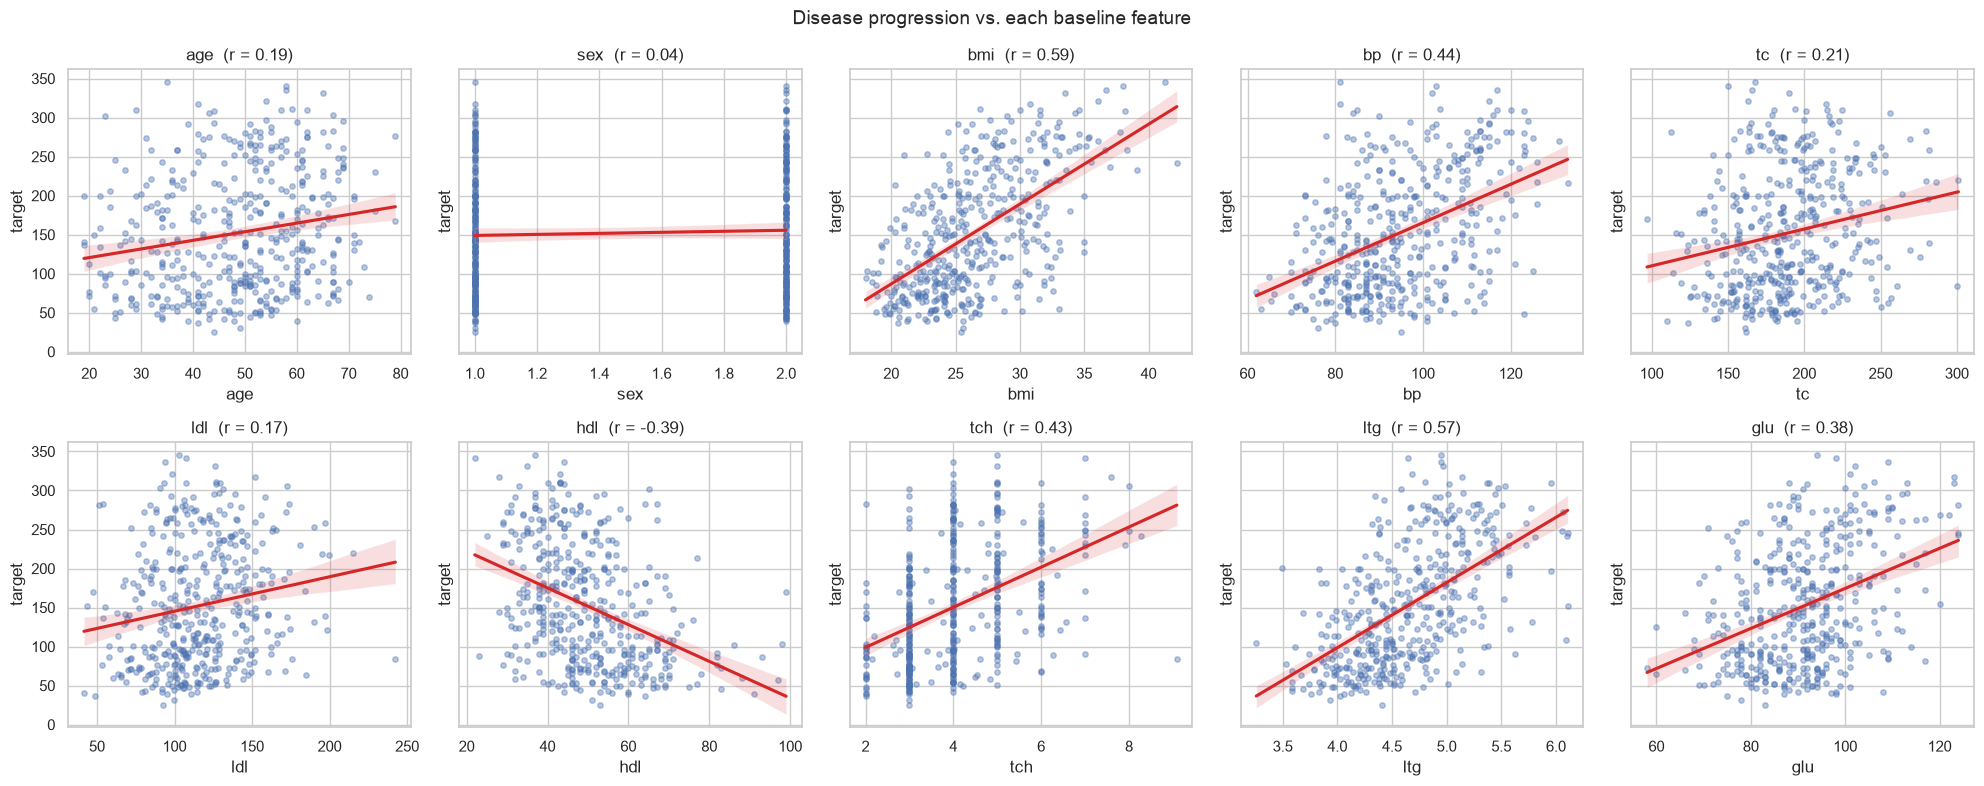

In [10]:
fig, axes = plt.subplots(2, 5, figsize=(20, 8), sharey=True)
for ax, col in zip(axes.flat, df.columns.drop("target")):
    sns.regplot(data=df, x=col, y="target", ax=ax, scatter_kws={"alpha": 0.4, "s": 15},
                line_kws={"color": "tab:red"})
    ax.set_title(f"{col}  (r = {df[col].corr(df['target']):.2f})")
fig.suptitle("Disease progression vs. each baseline feature", fontsize=14)
fig.tight_layout()
plt.show()

### 3.5 Correlation matrix

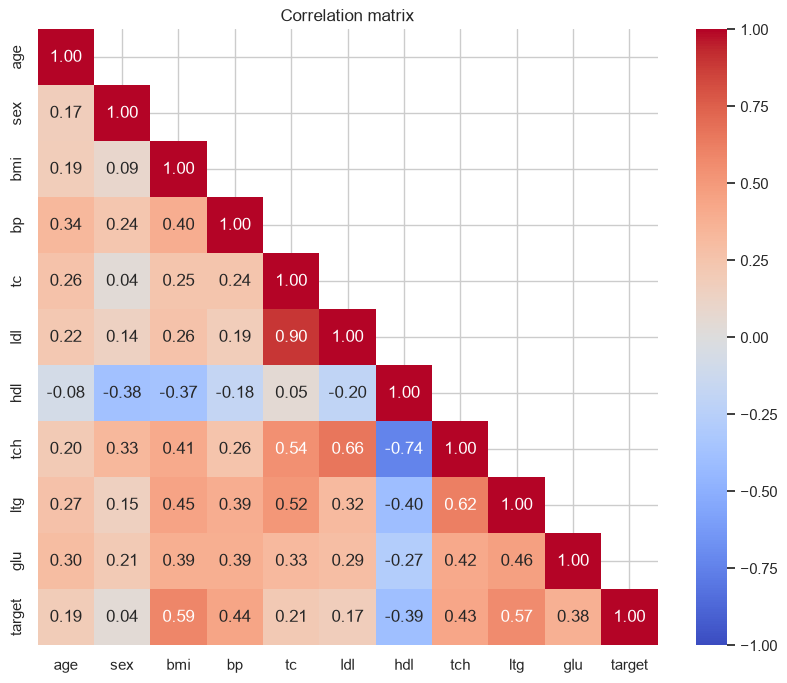

,corr with target
bmi,0.586
ltg,0.566
bp,0.441
tch,0.430
hdl,-0.395
glu,0.382
tc,0.212
age,0.188
ldl,0.174
sex,0.043


In [11]:
corr = df.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            mask=np.triu(np.ones_like(corr, dtype=bool), k=1))
plt.title("Correlation matrix")
plt.show()

corr["target"].drop("target").sort_values(key=abs, ascending=False).to_frame("corr with target")

### 3.6 What I found in the EDA

- **The dataset is small but clean:** 442 patients, 10 numeric features, no missing values and no
  duplicate rows.
- **The target** goes from 25 to 346 (mean about 152, median about 140). It's skewed to the right, so
  there are fewer patients with very high progression. That means the models have fewer examples of
  the highest-risk patients to learn from.
- **Strongest features:** `bmi` (r = 0.59) and `ltg` (r = 0.57), then `bp` (0.44), `tch` (0.43),
  `hdl` (−0.39) and `glu` (0.38). `hdl` is negative, which makes sense because HDL is the "good"
  cholesterol. BMI is the strongest, which is why I use it in Part 2.
- **Weak features:** `sex` (0.04), `ldl` (0.17), `age` (0.19) and `tc` (0.21) have only a weak linear
  relationship with the target on their own.
- **Some features overlap:** `tc` and `ldl` have r = 0.90, so they carry almost the same information.
  `tch` is also strongly related to `hdl` (−0.74), `ldl` (0.66) and `ltg` (0.62), which makes sense
  because `tch` is itself a cholesterol ratio.
- **Scatter plots:** even BMI has a lot of spread around the trend line. So I don't expect one feature
  on its own to explain most of the variation (BMI's r² is only about 0.35).
- **The features are on very different scales** (for example `tc` is around 190 and `ltg` is around
  4.6), so I'll need to scale them for kNN.
- `tch` is mostly whole numbers from 2 to 7, so it behaves almost like a category. `hdl` and `tch` are
  the most right-skewed features.
- **There are only a few outliers** (at most 9 per feature using the IQR rule, mostly in `glu`, `tc`,
  `ldl` and `hdl`). The values look like real measurements, not typing mistakes.

## 4. Data cleaning

The EDA showed the data is already in good shape, so I didn't need to do much:

| Check | What I found | What I did |
|---|---|---|
| Missing values | none | nothing to fill in |
| Duplicate rows | none | nothing to remove |
| Outliers | a few, but realistic values | **kept them** – they're real patients, and with only 442 rows I don't want to throw data away |
| `sex` | coded as 1 and 2 | changed it to 0 and 1 so it works as a simple yes/no variable |
| Feature scales | very different | I scale inside each model's pipeline instead of here, so the scaler only learns from the training data (this avoids data leakage) |

I decide which features to use for the multivariate models at the start of Part 3.

In [12]:
df_clean = df.copy()
df_clean["sex"] = (df_clean["sex"] == 2).astype(int)

assert df_clean.isna().sum().sum() == 0
df_clean.describe().T[["min", "max", "mean"]]

,min,max,mean
age,19.000,79.000,48.518
sex,0.000,1.000,0.468
bmi,18.000,42.200,26.376
bp,62.000,133.000,94.647
tc,97.000,301.000,189.140
ldl,41.600,242.400,115.439
hdl,22.000,99.000,49.788
tch,2.000,9.090,4.070
ltg,3.258,6.107,4.641
glu,58.000,124.000,91.260


## 5. Train / validation / test split (75% / 10% / 15%)

I use `train_test_split` twice. First I take out 15% of the data as the test set. Then I split the
remaining 85% so that 10% of the *whole* dataset becomes the validation set (that's 10/85 of what's left).

- I use the **validation set** to compare the models and pick the best one.
- I only use the **test set** once, at the very end, on the model I picked. That way the test score is
  a fair estimate of how the model would do on new patients.

I also check that the target looks similar in all three sets.

In [13]:
from sklearn.model_selection import train_test_split

X = df_clean.drop(columns="target")
y = df_clean["target"]

X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.15, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.10 / 0.85, random_state=RANDOM_STATE
)

split_sizes = pd.DataFrame(
    {"rows": [len(X_train), len(X_val), len(X_test)]}, index=["train", "validation", "test"]
)
split_sizes["share"] = (split_sizes["rows"] / len(X)).map("{:.1%}".format)
split_sizes

,rows,share
train,330,74.7%
validation,45,10.2%
test,67,15.2%


In [14]:
pd.DataFrame({"train": y_train.describe(), "validation": y_val.describe(), "test": y_test.describe()}).T

,count,mean,std,min,25%,50%,75%,max
train,330.0,153.045,78.035,25.0,86.25,142.0,211.5,346.0
validation,45.0,153.289,75.285,49.0,96.00,141.0,217.0,308.0
test,67.0,146.866,74.469,42.0,88.50,129.0,201.0,310.0


# Part 2 – Univariate polynomial regression on BMI
## 6. Models: degree 0 to 5

For each degree from 0 to 5, I make a pipeline: `StandardScaler` → `PolynomialFeatures(degree)` →
`LinearRegression`.

- **Why I scale first:** BMI goes from about 18 to 42, so BMI⁵ reaches more than 100 million while
  BMI¹ stays around 30. Columns of such different sizes make the least-squares problem numerically
  unstable. Standardising BMI first (mean 0 and standard deviation 1, using the **training set only**)
  keeps all the powers on a similar scale.
- **One intercept only:** `PolynomialFeatures` adds a column of 1s (the bias), so I set
  `fit_intercept=False` in `LinearRegression`. The intercept is then just the weight on the column of 1s.
- Degree 0 has no BMI term, so it predicts the training average every time. This is my **baseline**.

In [15]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression

X_train_bmi, X_val_bmi, X_test_bmi = X_train[["bmi"]], X_val[["bmi"]], X_test[["bmi"]]


def bmi_poly_model(degree, scale=True):
    """Polynomial regression on BMI. The bias column from PolynomialFeatures is the only intercept."""
    steps = [("scale", StandardScaler())] if scale else []
    steps += [("poly", PolynomialFeatures(degree=degree, include_bias=True)),
              ("linreg", LinearRegression(fit_intercept=False))]
    return Pipeline(steps)


bmi_models = {degree: bmi_poly_model(degree).fit(X_train_bmi, y_train) for degree in range(6)}

**Checking that scaling fixes the problem.** After fitting, `LinearRegression` reports the *rank* of
the feature matrix: how many columns it could treat as independent. If the rank is lower than the number
of columns, some coefficients can't be estimated reliably. In the table below, with raw BMI the rank gets
stuck at 3 from degree 3 upwards, so degrees 3–5 lose numerical rank. With scaled BMI every model has full
rank.

In [16]:
raw_bmi_models = {d: bmi_poly_model(d, scale=False).fit(X_train_bmi, y_train) for d in range(6)}
pd.DataFrame({
    "columns (degree + 1)": [d + 1 for d in range(6)],
    "rank – raw BMI": [raw_bmi_models[d].named_steps["linreg"].rank_ for d in range(6)],
    "rank – scaled BMI": [bmi_models[d].named_steps["linreg"].rank_ for d in range(6)],
}, index=[f"Degree {d}" for d in range(6)])

,columns (degree + 1),rank – raw BMI,rank – scaled BMI
Degree 0,1,1,1
Degree 1,2,2,2
Degree 2,3,3,3
Degree 3,4,3,4
Degree 4,5,3,5
Degree 5,6,3,6


## 7. Compare the models on training and validation data

In [17]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_absolute_percentage_error


def regression_metrics(y_true, y_pred):
    """R², MAE and MAPE (as a percentage) for one set of predictions."""
    return {
        "R2": r2_score(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "MAPE (%)": 100 * mean_absolute_percentage_error(y_true, y_pred),
    }


def compare_models(models, X_tr, X_va):
    """One row per model with train and validation metrics side by side."""
    rows = {}
    for name, model in models.items():
        train = regression_metrics(y_train, model.predict(X_tr))
        val = regression_metrics(y_val, model.predict(X_va))
        rows[name] = {**{f"Train {k}": v for k, v in train.items()},
                      **{f"Val {k}": v for k, v in val.items()}}
    return pd.DataFrame(rows).T


bmi_results = compare_models(bmi_models, X_train_bmi, X_val_bmi)
bmi_results.index = [f"Degree {d}" for d in bmi_results.index]
bmi_results.round(3)

,Train R2,Train MAE,Train MAPE (%),Val R2,Val MAE,Val MAPE (%)
Degree 0,0.000,66.548,63.352,-0.000,63.447,58.793
Degree 1,0.354,52.278,48.462,0.449,41.998,40.445
Degree 2,0.355,52.267,48.448,0.449,41.758,40.310
Degree 3,0.355,52.223,48.356,0.447,41.741,40.259
Degree 4,0.358,51.944,47.964,0.449,41.953,40.241
Degree 5,0.359,51.814,47.831,0.454,42.083,40.340


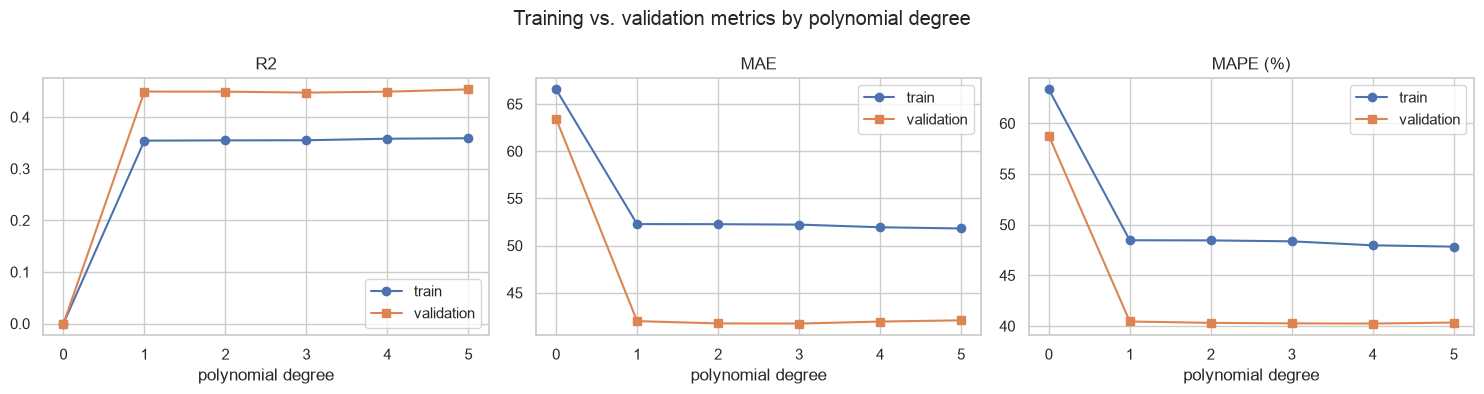

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, ["R2", "MAE", "MAPE (%)"]):
    ax.plot(range(6), bmi_results[f"Train {metric}"], "o-", label="train")
    ax.plot(range(6), bmi_results[f"Val {metric}"], "s-", label="validation")
    ax.set(title=metric, xlabel="polynomial degree")
    ax.legend()
fig.suptitle("Training vs. validation metrics by polynomial degree")
fig.tight_layout()
plt.show()

**What I noticed**
- **Degree 0 (the baseline)** has an R² of 0, which is expected since it only predicts the mean.
- The only big jump is from degree 0 to degree 1: validation R² goes from 0 to 0.449, and validation MAE
  drops from 63.4 to 42.0.
- **Degrees 2 to 5 are almost the same as degree 1.** Validation MAE stays between 41.74 and 42.08, and
  validation R² between 0.447 and 0.454. The relationship between BMI and progression looks linear.
- Training scores improve very slightly as the degree goes up (training MAE 52.28 → 51.81), but the
  validation scores don't improve in a consistent way. The extra flexibility mostly helps on the training
  data.
- Every model scores better on validation than on training. On this split, the 45 validation patients
  happen to be easier to predict. That doesn't tell me anything about overfitting by itself; it mainly
  shows that scores from 45 patients are noisy.
- MAPE is high for every model (about 40–48%). Most of it comes from patients with low target values,
  where even a small error is a large percentage.

## 8. Identify the best model

**My selection rule (set before looking at the test set):** I use **validation MAE** as the main metric,
because it's in the target's units and isn't distorted by small true values the way MAPE is. If several
models are within **1 MAE point** of the lowest validation MAE, I pick the **lowest degree** among them
(Occam's razor: fewer parameters, less risk of overfitting, easier to interpret).

In [19]:
MAE_TOLERANCE = 1.0  # MAE points

best_val_mae = bmi_results["Val MAE"].min()
TOP_DEGREE = int(bmi_results["Val MAE"].idxmin().split()[-1])
BEST_DEGREE = min(d for d in range(6)
                  if bmi_results.loc[f"Degree {d}", "Val MAE"] <= best_val_mae + MAE_TOLERANCE)
best_bmi_model, top_bmi_model = bmi_models[BEST_DEGREE], bmi_models[TOP_DEGREE]

print(f"Lowest validation MAE: degree {TOP_DEGREE} ({best_val_mae:.3f})")
print(f"Lowest degree within {MAE_TOLERANCE} MAE point of it: degree {BEST_DEGREE} "
      f"({bmi_results.loc[f'Degree {BEST_DEGREE}', 'Val MAE']:.3f})")

pd.DataFrame({
    "best model": [bmi_results["Val R2"].idxmax(), bmi_results["Val MAE"].idxmin(),
                   bmi_results["Val MAPE (%)"].idxmin()],
    "best value": [bmi_results["Val R2"].max(), bmi_results["Val MAE"].min(),
                   bmi_results["Val MAPE (%)"].min()],
    f"degree {BEST_DEGREE} value": bmi_results.loc[f"Degree {BEST_DEGREE}",
                                                  ["Val R2", "Val MAE", "Val MAPE (%)"]].values,
}, index=["Val R2", "Val MAE", "Val MAPE (%)"]).round(3)

Lowest validation MAE: degree 3 (41.741)
Lowest degree within 1.0 MAE point of it: degree 1 (41.998)


,best model,best value,degree 1 value
Val R2,Degree 5,0.454,0.449
Val MAE,Degree 3,41.741,41.998
Val MAPE (%),Degree 4,40.241,40.445


- The lowest validation MAE belongs to **degree 3** (41.74), so that's the **top scorer**. The other metrics
  pick different winners (R²: degree 5, MAPE: degree 4), and all of them are within 0.26 MAE, 0.20% MAPE
  and 0.005 R² of degree 1.
- Degree 1 (41.998) is within 1 point of the top scorer, so by my rule **I choose degree 1 (a straight line
  on BMI)**.
- I keep the top scorer (degree 3) next to it in the following steps as a comparison.

## 9. Evaluate the chosen model on the test set

I haven't used the test set for any decisions, so this gives a fair estimate of how the chosen model
would do on new patients. I also show the top scorer next to it for comparison (this doesn't change
my choice, which was already made on validation).

In [20]:
pd.DataFrame({
    f"Degree {BEST_DEGREE} (chosen) – train": regression_metrics(y_train, best_bmi_model.predict(X_train_bmi)),
    f"Degree {BEST_DEGREE} (chosen) – validation": regression_metrics(y_val, best_bmi_model.predict(X_val_bmi)),
    f"Degree {BEST_DEGREE} (chosen) – test": regression_metrics(y_test, best_bmi_model.predict(X_test_bmi)),
    f"Degree {TOP_DEGREE} (top scorer) – test": regression_metrics(y_test, top_bmi_model.predict(X_test_bmi)),
}).T.round(3)

,R2,MAE,MAPE (%)
Degree 1 (chosen) – train,0.354,52.278,48.462
Degree 1 (chosen) – validation,0.449,41.998,40.445
Degree 1 (chosen) – test,0.204,54.934,48.750
Degree 3 (top scorer) – test,0.207,54.629,48.541


**Test results for the chosen model:** R² = 0.204, MAE = 54.93, MAPE = 48.75%.

- The test scores are clearly worse than validation (R² 0.449 → 0.204, MAE 42.0 → 54.9) but close to the
  training scores (MAE 52.3, MAPE 48.5%). On this split the validation set was optimistic. With such
  small sets I can't tell how much of the gap is just chance; cross-validation would give a more stable
  estimate.
- The top scorer (degree 3) is almost the same on test (R² 0.207, MAE 54.63). On this split, choosing the
  simpler model cost about 0.3 MAE points.
- An average error of about 55 points, when the target's standard deviation is about 77, shows that BMI
  alone is a weak predictor.

## 10. Plot the train, validation and test data with the model fit

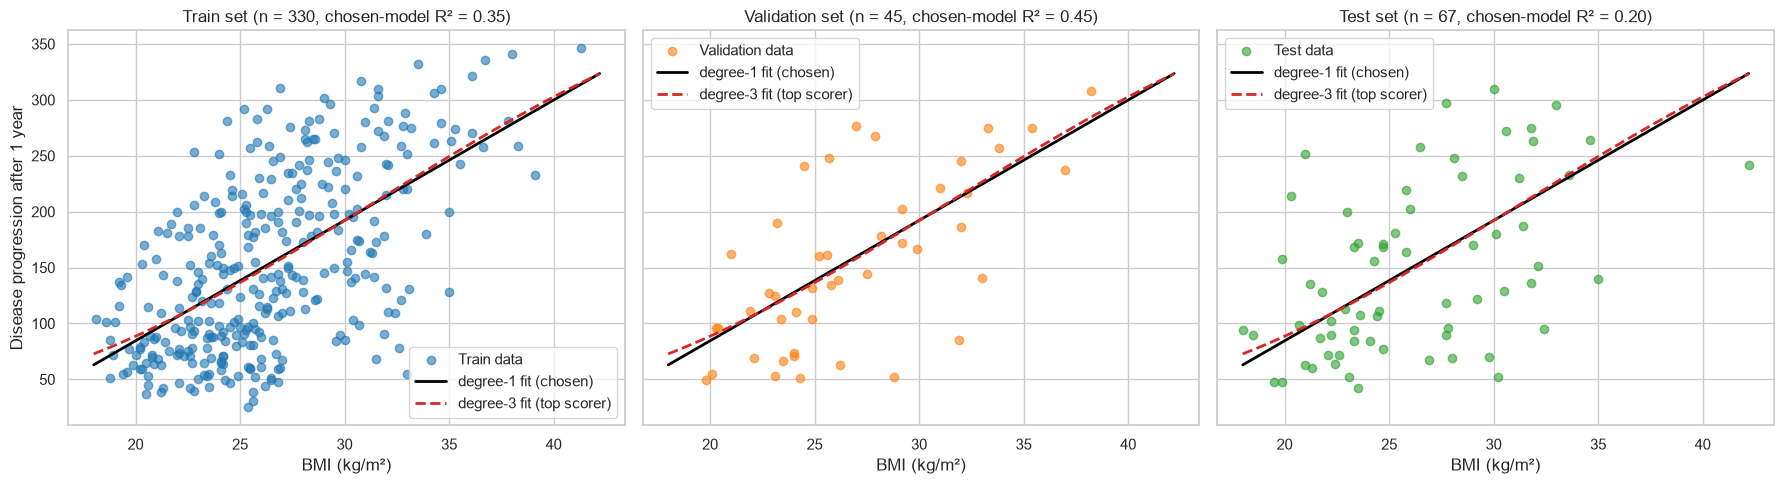

In [21]:
bmi_grid = pd.DataFrame({"bmi": np.linspace(X["bmi"].min(), X["bmi"].max(), 200)})
bmi_fit = best_bmi_model.predict(bmi_grid)
top_fit = top_bmi_model.predict(bmi_grid)

splits = [("Train", X_train_bmi, y_train, "tab:blue"),
          ("Validation", X_val_bmi, y_val, "tab:orange"),
          ("Test", X_test_bmi, y_test, "tab:green")]

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)
for ax, (name, X_split, y_split, color) in zip(axes, splits):
    r2 = r2_score(y_split, best_bmi_model.predict(X_split))
    ax.scatter(X_split["bmi"], y_split, alpha=0.6, color=color, label=f"{name} data")
    ax.plot(bmi_grid["bmi"], bmi_fit, color="black", lw=2, label=f"degree-{BEST_DEGREE} fit (chosen)")
    ax.plot(bmi_grid["bmi"], top_fit, color="tab:red", lw=2, ls="--",
            label=f"degree-{TOP_DEGREE} fit (top scorer)")
    ax.set(title=f"{name} set (n = {len(y_split)}, chosen-model R² = {r2:.2f})", xlabel="BMI (kg/m²)")
    ax.legend()
axes[0].set_ylabel("Disease progression after 1 year")
fig.tight_layout()
plt.show()

The line follows the upward trend in all three sets, but the points are very spread out around it. For
example, patients with a BMI between 24 and 26 have actual progression anywhere from 25 to 292. The test
set also contains the most extreme BMI (about 42), where the line over-predicts.

The degree-3 curve (red, dashed) sits almost on top of the straight line. It only separates slightly at
the low end of the BMI range, where there are few patients.

## 11. Equation of the best model

The model was fitted on standardised BMI, $z = (\text{BMI} - \mu)/\sigma$, using the training mean and
standard deviation. To report the equation in **original BMI units**, I substitute $z$ back into the
fitted polynomial and expand it. I round the coefficients to two decimals for reporting only;
predictions always use the full-precision model.

In [22]:
from numpy.polynomial import Polynomial


def polynomial_in_bmi_units(model):
    """Rewrite the fitted polynomial in z = (BMI - mean) / std as a polynomial in raw BMI."""
    scaler = model.named_steps["scale"]
    mu, sigma = scaler.mean_[0], scaler.scale_[0]
    poly_in_z = Polynomial(model.named_steps["linreg"].coef_)
    return poly_in_z(Polynomial([-mu / sigma, 1 / sigma]))


def format_equation(poly, fmt=".2f"):
    terms = []
    for power, coef in enumerate(poly.coef):
        value = format(coef, fmt)
        terms.append(value if power == 0 else f"{value}·BMI" + (f"^{power}" if power > 1 else ""))
    return "progression = " + " + ".join(terms).replace("+ -", "- ")


scaler = best_bmi_model.named_steps["scale"]
print(f"Training BMI mean = {scaler.mean_[0]:.4f}, std = {scaler.scale_[0]:.4f}")
print("Coefficients on scaled BMI:", best_bmi_model.named_steps["linreg"].coef_.round(4))

best_poly = polynomial_in_bmi_units(best_bmi_model)
print("\nChosen model in BMI units:", format_equation(best_poly))

check_bmi = pd.DataFrame({"bmi": [20.0, 30.0, 40.0]})
print("Full-precision equation matches model.predict():",
      np.allclose(best_poly(check_bmi["bmi"]), best_bmi_model.predict(check_bmi)))

Training BMI mean = 26.3670, std = 4.3067
Coefficients on scaled BMI: [153.0455  46.3744]

Chosen model in BMI units: progression = -130.87 + 10.77·BMI
Full-precision equation matches model.predict(): True


$$\widehat{\text{progression}} = -130.87 + 10.77 \times \text{BMI}$$

- **Slope:** for every extra 1 kg/m² of BMI, the model predicts about 10.77 more units of progression
  after one year.
- **Intercept:** −130.87 is what the model would predict at BMI = 0, which isn't a real BMI. It only sets
  where the line sits, so I don't interpret it on its own. Within the BMI range in the data (18–42) the
  predictions go from about 63 to 323.
- The check above confirms that the full-precision equation gives the same predictions as `model.predict()`.

**Top scorer (degree 3) for comparison.** Here is its equation in BMI units, first with two decimals and
then with more precision:

In [23]:
top_poly = polynomial_in_bmi_units(top_bmi_model)
print("2 decimals: ", format_equation(top_poly, ".2f"))
print("Scientific: ", format_equation(top_poly, ".3e"))

2 decimals:  progression = 88.08 - 11.48·BMI + 0.73·BMI^2 - 0.01·BMI^3
Scientific:  progression = 8.808e+01 - 1.148e+01·BMI + 7.296e-01·BMI^2 - 7.711e-03·BMI^3


Rounded to two decimals, the BMI³ coefficient becomes −0.01 instead of −0.0077. BMI³ is about 64,000 at
BMI 40, so that small rounding changes the prediction there by roughly 150 units. **Two decimals are
sufficient for the degree-1 equation, but not for the degree-3 one.** That's another point in favour of
the simpler model.

## 12. Predict progression for a chosen BMI value

I picked BMI = 30 kg/m² because that's the cut-off for obesity.

In [24]:
bmi_value = pd.DataFrame({"bmi": [30.0]})
predicted = best_bmi_model.predict(bmi_value)[0]
print(f"Chosen model (degree {BEST_DEGREE}) prediction for BMI = 30: {predicted:.2f}")
print(f"Top scorer (degree {TOP_DEGREE}) prediction for BMI = 30:   {top_bmi_model.predict(bmi_value)[0]:.2f}")

Chosen model (degree 1) prediction for BMI = 30: 192.17
Top scorer (degree 3) prediction for BMI = 30:   192.03


The prediction is **192.17 progression units** for a BMI of 30. The model's average absolute error on the
test set is about 55 units. The degree-3 model gives almost the same prediction (192.03).

## 13. Number of trainable parameters per model

In [25]:
param_table = pd.DataFrame([
    {
        "model": f"Degree {degree}",
        "features (get_feature_names_out; z = scaled BMI)":
            ", ".join(model.named_steps["poly"].get_feature_names_out(["z"])),
        "trainable parameters": model.named_steps["linreg"].coef_.size,
    }
    for degree, model in bmi_models.items()
]).set_index("model")
param_table

,features (get_feature_names_out; z = scaled BMI),trainable parameters
model,,
Degree 0,1,1
Degree 1,"1, z",2
Degree 2,"1, z, z^2",3
Degree 3,"1, z, z^2, z^3",4
Degree 4,"1, z, z^2, z^3, z^4",5
Degree 5,"1, z, z^2, z^3, z^4, z^5",6


A degree-*d* polynomial in one variable, $\hat y = w_0 + w_1z + w_2z^2 + \dots + w_dz^d$, has
**d + 1 trainable parameters**: one weight for each power from $z^0$ (the column of 1s, which is the
intercept) up to $z^d$. So my six models have 1, 2, 3, 4, 5 and 6 parameters. Here $z$ is the scaled BMI,
which is why `get_feature_names_out` is given the name `z`.

- Degree 0 only learns the intercept, which ends up being the training mean (153.05).
- My chosen degree-1 model learns 2 weights on scaled BMI (153.05 and 46.37). Rewritten in BMI units they
  become the intercept −130.87 and slope 10.77: the same two parameters, just expressed differently.
- The extra parameters in degrees 2–5 didn't improve the validation scores in any meaningful way.

## 14. Conclusions – Part 2
### 14.1 Where does the model fail?

To see where the model goes wrong, I look at its errors on the test set.

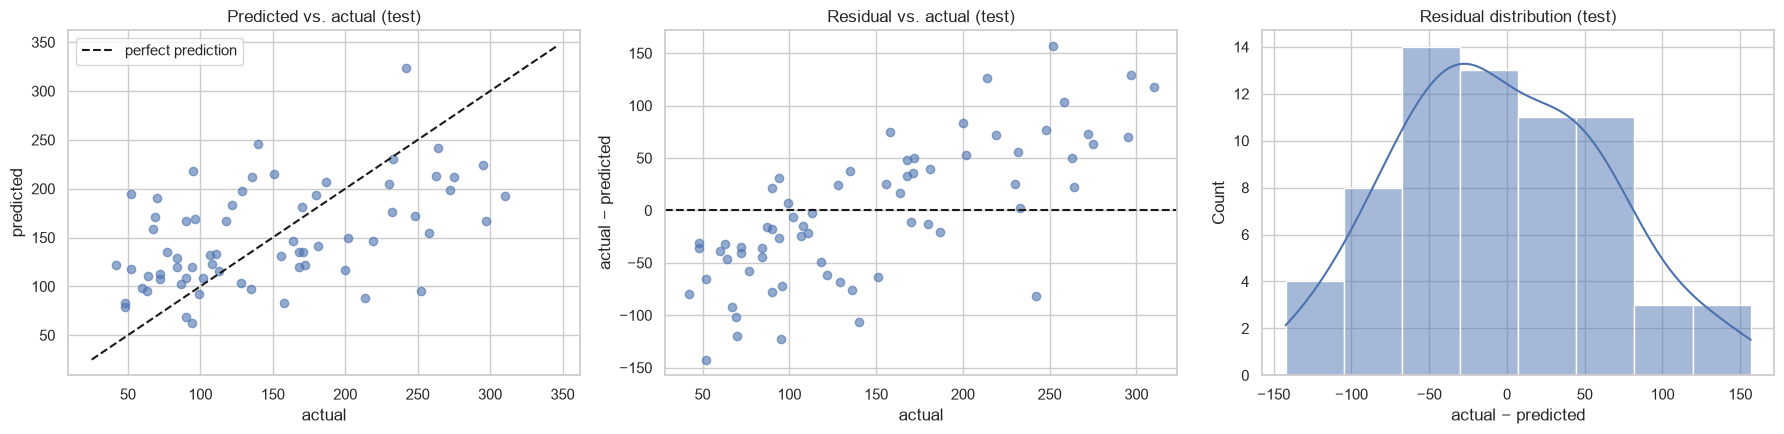

In [26]:
test_pred = best_bmi_model.predict(X_test_bmi)
residuals = y_test - test_pred

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].scatter(y_test, test_pred, alpha=0.6)
axes[0].plot([y.min(), y.max()], [y.min(), y.max()], "k--", label="perfect prediction")
axes[0].set(title="Predicted vs. actual (test)", xlabel="actual", ylabel="predicted")
axes[0].legend()
axes[1].scatter(y_test, residuals, alpha=0.6)
axes[1].axhline(0, color="k", ls="--")
axes[1].set(title="Residual vs. actual (test)", xlabel="actual", ylabel="actual − predicted")
sns.histplot(residuals, kde=True, ax=axes[2])
axes[2].set(title="Residual distribution (test)", xlabel="actual − predicted")
fig.tight_layout()
plt.show()

In [27]:
target_band = pd.qcut(y_test, 3, labels=["low", "medium", "high"])
pd.DataFrame({"actual": y_test, "predicted": test_pred, "abs error": residuals.abs(),
              "APE (%)": 100 * residuals.abs() / y_test, "band": target_band}) \
    .groupby("band", observed=True).agg(n=("actual", "size"), mean_actual=("actual", "mean"),
                                        mean_predicted=("predicted", "mean"),
                                        MAE=("abs error", "mean"), MAPE=("APE (%)", "mean")).round(1)

,n,mean_actual,mean_predicted,MAE,MAPE
band,,,,,
low,23,72.3,124.8,57.1,86.4
medium,22,134.1,146.7,40.1,30.2
high,22,237.5,180.5,67.5,27.9


**Using it as a screening tool.** If I flag a patient whenever their predicted progression is above
the training median (142), how many of the patients who really are above the median do I catch?
(The median is a statistical cut-off, not a clinical one.)

In [28]:
from sklearn.metrics import confusion_matrix, classification_report

RISK_THRESHOLD = y_train.median()
actual_high = (y_test > RISK_THRESHOLD).astype(int)
flagged_high = (test_pred > RISK_THRESHOLD).astype(int)

print(f"Cut-off (training median): {RISK_THRESHOLD}")
print(pd.DataFrame(confusion_matrix(actual_high, flagged_high),
                   index=["actual ≤ median", "actual > median"],
                   columns=["flagged ≤ median", "flagged > median"]))
print(classification_report(actual_high, flagged_high, target_names=["≤ median", "> median"]))

Cut-off (training median): 142.0
                 flagged ≤ median  flagged > median
actual ≤ median                25                12
actual > median                10                20
              precision    recall  f1-score   support

    ≤ median       0.71      0.68      0.69        37
    > median       0.62      0.67      0.65        30

    accuracy                           0.67        67
   macro avg       0.67      0.67      0.67        67
weighted avg       0.67      0.67      0.67        67



**What I found**
- **Predictions are pulled towards the middle.** For the lowest third of test patients the model predicts
  about 52 units too high on average (MAPE ≈ 86%), and for the highest third about 57 units too low.
- **The biggest errors are in the high-progression group** (MAE ≈ 68). Those are exactly the patients a
  screening tool most needs to catch.
- **MAPE is mostly driven by the low values.** A 50-unit error on a patient whose true value is 40 counts
  as 125%.
- **Extreme BMI values** (like the test patient at BMI ≈ 42) are hard because there are very few training
  patients with a BMI that high.
- **As a screening tool** (flagging predictions above 142), the model catches 20 of the 30 above-median
  test patients (recall 0.67) and misses 10. 12 of the 32 patients it flags are false alarms
  (precision 0.62). Overall accuracy is 0.67.

### 14.2 Summary
- BMI is the strongest single predictor, and its relationship with progression is close to **linear**.
  Following my selection rule, I chose degree 1. The top scorer on validation (degree 3) was almost
  identical on the test set.
- My chosen model is $\widehat{\text{progression}} = -130.87 + 10.77 \times \text{BMI}$.
- On the test set it gets **R² = 0.20, MAE = 54.9 and MAPE = 48.8%**. That's better than predicting the
  mean, but BMI alone explains only a small part of the variation in progression.

### 14.3 Limitations
- **One feature isn't enough for a disease with many causes.** Blood pressure, triglycerides (`ltg`) and
  HDL are also related to progression, and this model ignores them. I add them in Part 3.
- **The dataset is small, so the scores are noisy.** With 45 validation and 67 test patients the scores
  change a lot between sets (validation R² 0.45 vs. test 0.20). k-fold cross-validation would be more
  reliable.
- **Correlation isn't causation.** The slope describes a pattern in this group of patients. It doesn't mean
  that lowering someone's BMI by 1 would lower their progression by 10.77.
- **Polynomial features need scaling.** Without it, degrees 3–5 on raw BMI lost numerical rank. I fixed
  this by standardising BMI inside the pipeline.
- **It may not generalise.** All 442 patients come from one study, so I don't know how well this would
  work on other populations.

### 14.4 Connecting to the workshops
- *Performance metrics:* R² and MAE describe the average size of the errors, but for screening the
  **confusion matrix** matters more, especially **recall** for above-median patients. Lowering the
  cut-off would catch more of them but raise more false alarms.
- *Logistic regression:* treating the problem directly as above-median vs. not gives a **probability**,
  so the decision threshold can be chosen with screening in mind (Part 3).
- *kNN:* a model that uses several scaled features might pick up patterns a single straight line can't,
  as long as *k* is chosen carefully (Part 3).

# Part 3 – Multivariate models
## Feature selection

In the EDA (on the full dataset) `tc` and `ldl` looked almost redundant. To make sure the feature
decision doesn't use information from the validation or test sets, I recheck the numbers on the
**training set only**.

In [29]:
train_corr = X_train.assign(target=y_train).corr()
pd.DataFrame({"correlation (training set)": [train_corr.loc["tc", "ldl"],
                                             train_corr.loc["tc", "target"],
                                             train_corr.loc["ldl", "target"]]},
             index=["tc vs ldl", "tc vs target", "ldl vs target"]).round(3)

,correlation (training set)
tc vs ldl,0.895
tc vs target,0.203
ldl vs target,0.173


On the training set, `tc` and `ldl` have a correlation of **0.895**, and each is only weakly related to the
target (0.203 and 0.173).

- Such a strong correlation **suggests** that `tc` and `ldl` carry much of the same information, so I
  **drop `tc`** to reduce redundancy. This also makes the polynomial and logistic coefficients more stable.
- But correlation doesn't **prove** that `tc` adds nothing. About 20% of its variance isn't shared with
  `ldl` (1 − 0.895² ≈ 0.20), and that part could still carry some signal. I accept that small risk in
  exchange for a simpler feature set.
- **I keep everything else**, including the weakly correlated `sex`, `age` and `ldl`. Correlation only
  measures straight-line relationships one feature at a time, so these features could still help in
  combination with others, or in non-linear models like trees and kNN.

In [30]:
FEATURES = [c for c in X.columns if c != "tc"]
X_train_mv, X_val_mv, X_test_mv = X_train[FEATURES], X_val[FEATURES], X_test[FEATURES]
FEATURES

['age', 'sex', 'bmi', 'bp', 'ldl', 'hdl', 'tch', 'ltg', 'glu']

## 6. Models

I picked two settings for each type of model:

| Model type | Model A | Model B | Why I chose these |
|---|---|---|---|
| Polynomial regression | degree 2 | degree 3 | degree 2 adds squares and interactions; degree 3 tests whether even more flexibility helps |
| Decision tree | `max_depth=3` | `max_depth=5` | a shallow, simple tree vs. a deeper, more flexible one |
| kNN | `k=5` | `k=15` | few neighbours (more detailed but noisier) vs. more neighbours (smoother) |
| Logistic regression | `C=1` | `C=0.01` | the default vs. strong regularisation |

- I put a `StandardScaler` in the pipeline for the polynomial, kNN and logistic models. kNN needs it
  because it's based on distances. The polynomial models need it for the same numerical reason as in
  Part 2. Trees split on one feature at a time, so they don't need scaling.
- In the polynomial pipelines I use `include_bias=False`, so `LinearRegression`'s intercept is the only
  intercept.
- **Logistic regression is a classifier**, so I turn the target into a label: **1 = above-median
  progression** (above 142, the training median). This is a statistical cut-off that gives balanced
  classes (162 vs. 168 training patients). It is **not** a clinical threshold. I take the median from the
  training set only, so no information leaks in from the validation or test sets.

In [31]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LogisticRegression


def poly_model(degree):
    # include_bias=False: LinearRegression's intercept is the only intercept
    return Pipeline([("scale", StandardScaler()),
                     ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
                     ("linreg", LinearRegression())])


def knn_model(k):
    return Pipeline([("scale", StandardScaler()), ("knn", KNeighborsRegressor(n_neighbors=k))])


def logistic_model(C):
    return Pipeline([("scale", StandardScaler()), ("logreg", LogisticRegression(C=C))])


mv_models = {
    "Polynomial (deg 2)": poly_model(2),
    "Polynomial (deg 3)": poly_model(3),
    "Tree (depth 3)": DecisionTreeRegressor(max_depth=3, random_state=RANDOM_STATE),
    "Tree (depth 5)": DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE),
    "kNN (k=5)": knn_model(5),
    "kNN (k=15)": knn_model(15),
}
for model in mv_models.values():
    model.fit(X_train_mv, y_train)

# Binary labels for logistic regression: 1 = above-median progression
y_train_cls = (y_train > RISK_THRESHOLD).astype(int)
y_val_cls = (y_val > RISK_THRESHOLD).astype(int)
y_test_cls = (y_test > RISK_THRESHOLD).astype(int)

log_models = {"Logistic (C=1)": logistic_model(1.0), "Logistic (C=0.01)": logistic_model(0.01)}
for model in log_models.values():
    model.fit(X_train_mv, y_train_cls)

print("Class balance (train):", y_train_cls.value_counts().to_dict())

Class balance (train): {0: 168, 1: 162}


## 7. Compare the models on training and validation data
### 7.1 Regression models (R², MAE, MAPE)

In [32]:
mv_results = compare_models(mv_models, X_train_mv, X_val_mv)
mv_results.round(3)

,Train R2,Train MAE,Train MAPE (%),Val R2,Val MAE,Val MAPE (%)
Polynomial (deg 2),0.582,40.205,35.662,0.547,39.738,43.550
Polynomial (deg 3),0.802,26.244,23.361,-2.042,87.433,81.991
Tree (depth 3),0.533,43.588,37.748,0.413,42.078,43.651
Tree (depth 5),0.702,33.406,29.331,0.184,49.724,51.230
kNN (k=5),0.597,39.199,33.962,0.412,46.684,47.461
kNN (k=15),0.509,44.139,39.179,0.569,39.167,39.858


### 7.2 Logistic regression (classification metrics and log-loss)

R², MAE and MAPE don't work for 0/1 labels (MAPE would even divide by zero), so for logistic regression I
use the classification metrics from the *Performance Metrics* workshop:
- **Recall:** the share of above-median patients that get flagged. This is the key metric for screening.
- **Precision, accuracy and F1** show the cost of those flags (false alarms).
- **ROC-AUC:** how well the predicted probabilities rank above-median patients above the others, whatever
  threshold I pick.
- **Log-loss:** this scores the **predicted probabilities themselves**. It heavily penalises confident
  mistakes (for example, saying 95% when the answer is "no"). Lower is better, and unlike accuracy it
  doesn't depend on the 0.5 threshold.

In [33]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, log_loss)


def classification_metrics(y_true, y_pred, y_proba=None):
    metrics = {"Accuracy": accuracy_score(y_true, y_pred),
               "Precision": precision_score(y_true, y_pred),
               "Recall": recall_score(y_true, y_pred),
               "F1": f1_score(y_true, y_pred)}
    if y_proba is not None:
        metrics["ROC-AUC"] = roc_auc_score(y_true, y_proba)
        metrics["Log-loss"] = log_loss(y_true, y_proba)
    return metrics


log_results = pd.DataFrame({
    name: {**{f"Train {k}": v for k, v in classification_metrics(
               y_train_cls, m.predict(X_train_mv), m.predict_proba(X_train_mv)[:, 1]).items()},
           **{f"Val {k}": v for k, v in classification_metrics(
               y_val_cls, m.predict(X_val_mv), m.predict_proba(X_val_mv)[:, 1]).items()}}
    for name, m in log_models.items()
}).T
log_results.round(3)

,Train Accuracy,Train Precision,Train Recall,Train F1,Train ROC-AUC,Train Log-loss,Val Accuracy,Val Precision,Val Recall,Val F1,Val ROC-AUC,Val Log-loss
Logistic (C=1),0.736,0.733,0.728,0.731,0.840,0.487,0.822,0.792,0.864,0.826,0.915,0.394
Logistic (C=0.01),0.730,0.724,0.728,0.726,0.824,0.540,0.844,0.826,0.864,0.844,0.925,0.482


### 7.3 All models as screening tools

To compare all eight models on common ground, I also turn the regression predictions into flags using
the same cut-off (predicted progression > 142). Logistic regression uses its default 0.5 probability
threshold here.

In [34]:
screening = {}
for name, m in mv_models.items():
    screening[name] = classification_metrics(y_val_cls, (m.predict(X_val_mv) > RISK_THRESHOLD).astype(int))
for name, m in log_models.items():
    screening[name] = classification_metrics(y_val_cls, m.predict(X_val_mv))
pd.DataFrame(screening).T.add_prefix("Val ").round(3)

,Val Accuracy,Val Precision,Val Recall,Val F1
Polynomial (deg 2),0.800,0.741,0.909,0.816
Polynomial (deg 3),0.578,0.560,0.636,0.596
Tree (depth 3),0.800,0.760,0.864,0.809
Tree (depth 5),0.733,0.727,0.727,0.727
kNN (k=5),0.711,0.680,0.773,0.723
kNN (k=15),0.778,0.731,0.864,0.792
Logistic (C=1),0.822,0.792,0.864,0.826
Logistic (C=0.01),0.844,0.826,0.864,0.844


**What I noticed**
- **Polynomial degree 3 overfits badly.** It has 219 coefficients plus an intercept for only 330 training
  patients. Its training R² is 0.80, but its validation R² is −2.04, far worse than predicting the mean.
- **The depth-5 tree also overfits** (training R² 0.70 vs. validation 0.18). The depth-3 tree is more
  balanced (0.53 vs. 0.41).
- **kNN with k = 15** has the best validation scores (R² 0.569, MAE 39.17, MAPE 39.86%). On this split its
  validation score is even higher than its training score (0.509). I don't read that as proof that it
  can't overfit; it just generalised at least as well as it fit here. kNN with k = 5 fits the training
  data more closely (0.597) but does worse on validation (0.412). This is the bias–variance trade-off.
- **Polynomial degree 2** comes a close second (validation MAE 39.74).
- **Logistic regression:** C = 0.01 has slightly higher validation accuracy (0.844 vs. 0.822), F1 (0.844
  vs. 0.826) and ROC-AUC (0.925 vs. 0.915), but a clearly **worse log-loss (0.482 vs. 0.394)**. Strong
  regularisation shrinks the coefficients, which pushes all probabilities towards 0.5. The ranking stays
  good, but the probabilities themselves become less informative. Both have the same validation recall
  (0.864).
- **As screening tools** (table 7.3), polynomial degree 2 has the highest validation recall (0.909) and
  logistic C = 0.01 the highest accuracy and F1. There are only 22 above-median patients in the validation
  set, so one patient changes recall by about 0.045. These differences are small.

## 8. Identify the best models

**My selection rules (set before looking at the test set):**
- **Regression families (polynomial, tree, kNN):** the model with the lowest **validation MAE**, the same
  main metric as in Part 2.
- **Logistic regression:** the model with the lowest **validation log-loss**, because the screening tool
  relies on its probabilities and log-loss is the metric that judges probabilities directly.
- **Best regression model overall:** the lowest validation MAE across all families. (In Part 2 I preferred
  the lower degree when scores were close, because "simpler" was clear there. Across different families
  there's no single measure of simplicity, so here I go by validation MAE alone.)

In [35]:
families = {
    "Polynomial": ["Polynomial (deg 2)", "Polynomial (deg 3)"],
    "Decision tree": ["Tree (depth 3)", "Tree (depth 5)"],
    "kNN": ["kNN (k=5)", "kNN (k=15)"],
}
selected = {family: mv_results.loc[names, "Val MAE"].idxmin() for family, names in families.items()}
selected["Logistic regression"] = log_results["Val Log-loss"].idxmin()

best_mv_name = mv_results["Val MAE"].idxmin()
best_log_name = selected["Logistic regression"]
best_mv_model, best_log_model = mv_models[best_mv_name], log_models[best_log_name]

pd.DataFrame({
    "selected model": selected.values(),
    "selection metric": ["Val MAE"] * 3 + ["Val log-loss"],
    "value": [mv_results.loc[selected[f], "Val MAE"] for f in families]
             + [log_results.loc[best_log_name, "Val Log-loss"]],
}, index=selected.keys()).round(3)

,selected model,selection metric,value
Polynomial,Polynomial (deg 2),Val MAE,39.738
Decision tree,Tree (depth 3),Val MAE,42.078
kNN,kNN (k=15),Val MAE,39.167
Logistic regression,Logistic (C=1),Val log-loss,0.394


In [36]:
print("Best regression model overall (lowest validation MAE):", best_mv_name)

Best regression model overall (lowest validation MAE): kNN (k=15)


### Choosing the decision threshold (validation set only)

The default threshold of 0.5 treats a missed above-median patient and a false alarm as equally bad. For
screening, a miss is worse.

**Rule (validation set only):** I try the thresholds 0.50, 0.45, …, 0.20 and pick the **highest** one that
reaches a validation recall of at least **0.90**. I take the highest such threshold because going lower
than necessary just adds false alarms.

In [37]:
MIN_RECALL = 0.90
val_proba = best_log_model.predict_proba(X_val_mv)[:, 1]

threshold_rows = []
for t in np.round(np.arange(0.50, 0.19, -0.05), 2):
    pred = (val_proba >= t).astype(int)
    threshold_rows.append({"threshold": t, "Val recall": recall_score(y_val_cls, pred),
                           "Val precision": precision_score(y_val_cls, pred),
                           "Val accuracy": accuracy_score(y_val_cls, pred)})
threshold_table = pd.DataFrame(threshold_rows).set_index("threshold")

meets_target = threshold_table[threshold_table["Val recall"] >= MIN_RECALL]
THRESHOLD = meets_target.index.max() if len(meets_target) else 0.5
print(f"Chosen threshold: {THRESHOLD}")
threshold_table.round(3)

Chosen threshold: 0.35


,Val recall,Val precision,Val accuracy
threshold,,,
0.50,0.864,0.792,0.822
0.45,0.864,0.792,0.822
0.40,0.864,0.760,0.800
0.35,0.909,0.769,0.822
0.30,0.909,0.690,0.756
0.25,0.955,0.636,0.711
0.20,1.000,0.579,0.644


**0.35 is the highest threshold with a validation recall of at least 0.90** (0.909, i.e. 20 of the 22
above-median validation patients). Validation precision drops a little (0.792 → 0.769). I fix the threshold
at 0.35 now, and only then evaluate it on the test set below.

## 9. Evaluate the chosen models on the test set

In [38]:
pd.DataFrame({
    "BMI only – degree " + str(BEST_DEGREE) + " (Part 2)": regression_metrics(y_test, best_bmi_model.predict(X_test_bmi)),
    f"{best_mv_name} – train": regression_metrics(y_train, best_mv_model.predict(X_train_mv)),
    f"{best_mv_name} – validation": regression_metrics(y_val, best_mv_model.predict(X_val_mv)),
    f"{best_mv_name} – test": regression_metrics(y_test, best_mv_model.predict(X_test_mv)),
}).T.round(3)

,R2,MAE,MAPE (%)
BMI only – degree 1 (Part 2),0.204,54.934,48.750
kNN (k=15) – train,0.509,44.139,39.179
kNN (k=15) – validation,0.569,39.167,39.858
kNN (k=15) – test,0.409,45.215,40.617


In [39]:
log_test_proba = best_log_model.predict_proba(X_test_mv)[:, 1]
log_test_pred = (log_test_proba >= THRESHOLD).astype(int)

pd.DataFrame({
    f"BMI only (flag > {RISK_THRESHOLD:.0f})": classification_metrics(y_test_cls, flagged_high),
    f"{best_mv_name} (flag > {RISK_THRESHOLD:.0f})": classification_metrics(
        y_test_cls, (best_mv_model.predict(X_test_mv) > RISK_THRESHOLD).astype(int)),
    f"{best_log_name} (threshold 0.5)": classification_metrics(
        y_test_cls, (log_test_proba >= 0.5).astype(int), log_test_proba),
    f"{best_log_name} (threshold {THRESHOLD})": classification_metrics(
        y_test_cls, log_test_pred, log_test_proba),
}).T.round(3)

,Accuracy,Precision,Recall,F1,ROC-AUC,Log-loss
BMI only (flag > 142),0.672,0.625,0.667,0.645,NaN,NaN
kNN (k=15) (flag > 142),0.761,0.694,0.833,0.758,NaN,NaN
Logistic (C=1) (threshold 0.5),0.746,0.710,0.733,0.721,0.822,0.519
Logistic (C=1) (threshold 0.35),0.791,0.722,0.867,0.788,0.822,0.519


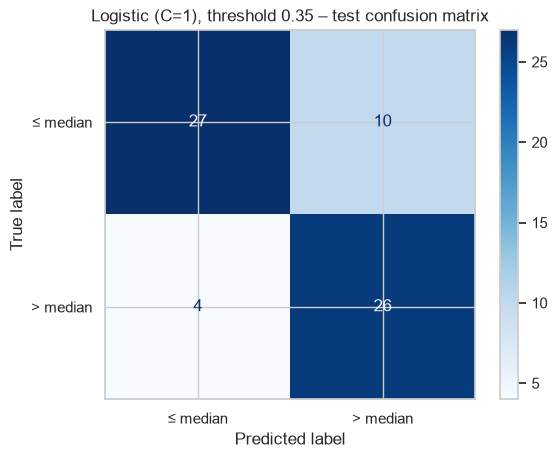

In [40]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test_cls, log_test_pred,
                                        display_labels=["≤ median", "> median"], cmap="Blues")
plt.title(f"{best_log_name}, threshold {THRESHOLD} – test confusion matrix")
plt.show()

**Test results**
- **kNN (k = 15): R² = 0.409, MAE = 45.2, MAPE = 40.6%.** Compared with BMI alone (R² 0.204, MAE 54.9),
  using the selected features roughly **doubles R²** and lowers the average error by about 10 units. As in
  Part 2, the test scores are worse than validation (R² 0.569) on this split, and a little below training
  (0.509).
- **Logistic regression (C = 1) at threshold 0.35:** accuracy 0.791, precision 0.722, **recall 0.867**
  (26 of the 30 above-median test patients), F1 0.788. At the default 0.5 the recall would have been 0.733
  (22 of 30), so the threshold chosen on validation carried over to the test set.
- **Probabilities:** test ROC-AUC is 0.822 and test log-loss is 0.519, worse than on validation (0.915 and
  0.394). The probabilities were less reliable on new patients than validation suggested.
- The kNN predictions turned into flags reach a test recall of 0.833 (25 of 30). Both selected multivariate
  models beat the BMI-only model on every metric shown.

## 10. Plots

A fitted curve can't be drawn on one axis for a model with 9 features (and plots aren't required for
the multivariate models). Instead I show **predicted vs. actual** for the best regression model and
the **ROC curve** for the selected logistic model on the test set.

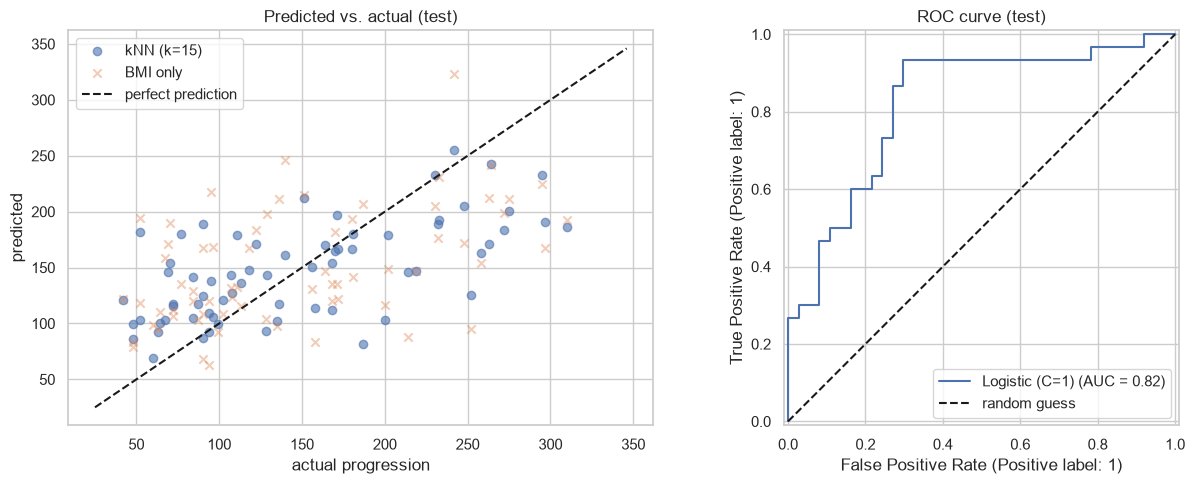

In [41]:
from sklearn.metrics import RocCurveDisplay

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_test, best_mv_model.predict(X_test_mv), alpha=0.6, label=best_mv_name)
axes[0].scatter(y_test, best_bmi_model.predict(X_test_bmi), alpha=0.4, marker="x", label="BMI only")
axes[0].plot([y.min(), y.max()], [y.min(), y.max()], "k--", label="perfect prediction")
axes[0].set(title="Predicted vs. actual (test)", xlabel="actual progression", ylabel="predicted")
axes[0].legend()
RocCurveDisplay.from_predictions(y_test_cls, log_test_proba, name=best_log_name, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", label="random guess")
axes[1].set_title("ROC curve (test)")
axes[1].legend()
fig.tight_layout()
plt.show()

- The kNN predictions are closer to the diagonal than the BMI-only predictions, but they only go from
  about 70 to 255. Because kNN averages 15 neighbours, it can't predict really extreme values, so patients
  with very high progression (> 250) are still under-predicted.
- The ROC curve is well above the random-guess line (AUC 0.82). My threshold of 0.35 sits at about 87%
  true-positive rate for 27% false-positive rate (10 of the 37 patients at or below the median were
  flagged).

## 11. Model equations

**kNN doesn't have an equation.** It's a *non-parametric* model: to predict a new patient, it finds
the 15 most similar training patients (by distance on the scaled features) and averages their target
values:

$$\widehat{\text{progression}}(x) = \frac{1}{15}\sum_{i \in N_{15}(x)} y_i$$

**Logistic regression** does have an equation. Here it is on the standardised features
$z_j = (x_j - \mu_j)/\sigma_j$:

In [42]:
logreg = best_log_model.named_steps["logreg"]
log_coefs = pd.Series(logreg.coef_[0], index=FEATURES)

terms = " ".join(f"{'+' if c >= 0 else '-'} {abs(c):.2f}·z_{name}" for name, c in log_coefs.items())
print(f"log-odds(above-median progression) = {logreg.intercept_[0]:.2f} {terms}")
print("P(above-median progression) = 1 / (1 + exp(-log-odds))\n")
log_coefs.sort_values(key=abs, ascending=False).round(2).to_frame("coefficient (standardised)")

log-odds(above-median progression) = 0.00 + 0.24·z_age - 0.58·z_sex + 0.65·z_bmi + 0.56·z_bp - 0.35·z_ldl - 0.51·z_hdl + 0.12·z_tch + 0.59·z_ltg + 0.06·z_glu
P(above-median progression) = 1 / (1 + exp(-log-odds))



,coefficient (standardised)
bmi,0.65
ltg,0.59
sex,-0.58
bp,0.56
hdl,-0.51
ldl,-0.35
age,0.24
tch,0.12
glu,0.06


Because the features are standardised, I can compare the coefficients directly. Each one is the change
in the log-odds of above-median progression when that feature goes up by one standard deviation, **while
the other features stay the same**.

- **BMI (0.65), `ltg` (0.59) and blood pressure (0.56)** increase the predicted risk the most, and
  **`hdl` (−0.51)** lowers it. This matches what the correlation matrix showed in the EDA.
- `sex` has a large weight (−0.58) even though its correlation with the target was close to 0: the group
  coded 1 has lower predicted risk *once the other features are taken into account*. This supports my
  decision to keep it.
- `ldl` is negative (−0.35) although its correlation with the target was positive. Correlated features
  like `ldl`, `tch` and `hdl` share credit in a multivariate model, so individual signs shouldn't be read
  as causal effects.

## 12. Prediction for an example patient

To compare with Part 2, I made up a "typical" patient by using the training-set median for every
feature, and then set **BMI = 30**.

In [43]:
patient = X_train_mv.median().to_frame().T
patient["bmi"] = 30.0
display(patient)

print(f"BMI-only model (Part 2):  {best_bmi_model.predict(patient[['bmi']])[0]:.2f}")
for family in families:
    print(f"{selected[family]:<24} {mv_models[selected[family]].predict(patient)[0]:.2f}")
print(f"{best_log_name:<24} P(above median) = {best_log_model.predict_proba(patient)[0, 1]:.2f}")

,age,sex,bmi,bp,ldl,hdl,tch,ltg,glu
0,50.0,0.0,30.0,93.0,112.3,48.0,4.0,4.63,91.0


BMI-only model (Part 2):  192.17
Polynomial (deg 2)       173.59
Tree (depth 3)           171.75
kNN (k=15)               170.80
Logistic (C=1)           P(above median) = 0.75


All the models put this patient above the 142 cut-off, but the multivariate models are less extreme than
BMI alone: polynomial degree 2 predicts 173.59, the depth-3 tree 171.75 and kNN 170.80, compared with
192.17 from BMI alone. This patient's other values are average, which pulls the prediction back towards
the middle. Logistic regression gives a 75% probability of above-median progression, so the patient would
be flagged at the 0.35 threshold.

## 13. Number of trainable parameters per model

In [44]:
def count_parameters(name, model):
    if "Polynomial" in name:
        n = model.named_steps["poly"].get_feature_names_out(FEATURES).size
        return n + 1, f"{n} polynomial coefficients + 1 intercept"
    if "Tree" in name:
        splits = model.tree_.node_count - model.get_n_leaves()
        leaves = model.get_n_leaves()
        return 2 * splits + leaves, f"{splits} splits × (feature, threshold) + {leaves} leaf values"
    if "kNN" in name:
        n = len(X_train_mv)
        return 0, f"no fitted coefficients – stores {n} × {len(FEATURES)} training features + {n} targets"
    if "Logistic" in name:
        lr = model.named_steps["logreg"]
        return lr.coef_.size + lr.intercept_.size, f"{lr.coef_.size} weights + 1 intercept"


param_rows = {name: count_parameters(name, m) for name, m in {**mv_models, **log_models}.items()}
pd.DataFrame(param_rows, index=["trainable parameters", "explanation"]).T

,trainable parameters,explanation
Polynomial (deg 2),55,54 polynomial coefficients + 1 intercept
Polynomial (deg 3),220,219 polynomial coefficients + 1 intercept
Tree (depth 3),22,"7 splits × (feature, threshold) + 8 leaf values"
Tree (depth 5),94,"31 splits × (feature, threshold) + 32 leaf values"
kNN (k=5),0,no fitted coefficients – stores 330 × 9 traini...
kNN (k=15),0,no fitted coefficients – stores 330 × 9 traini...
Logistic (C=1),10,9 weights + 1 intercept
Logistic (C=0.01),10,9 weights + 1 intercept


In [45]:
print("First 12 degree-2 terms:", mv_models["Polynomial (deg 2)"].named_steps["poly"]
      .get_feature_names_out(FEATURES)[:12])

First 12 degree-2 terms: ['age' 'sex' 'bmi' 'bp' 'ldl' 'hdl' 'tch' 'ltg' 'glu' 'age^2' 'age sex'
 'age bmi']


- **Polynomial:** with 9 features, `get_feature_names_out` gives **54** terms for degree 2 and **219** for
  degree 3 (every feature, square and product). Each gets one coefficient, plus the single intercept from
  `LinearRegression`: **55** and **220** parameters. Having 220 parameters for only 330 training patients
  explains why degree 3 overfits so badly.
- **Decision tree:** I use this counting convention: each split learns two values (which feature and the
  threshold) and each leaf stores one predicted value. Other conventions exist, for example counting only
  the leaves. Either way, depth 5 has roughly four times as many as depth 3, so it can memorise small
  groups of patients.
- **kNN:** **no fitted coefficients**. `k` is a hyperparameter I chose. kNN is a *lazy learner*: it stores
  the training features (330 × 9) and targets (330), and all the work happens when it predicts. In a sense,
  the stored training set is the model.
- **Logistic regression:** one weight per feature plus an intercept, so **10**.
- (The `StandardScaler` also learns a mean and standard deviation per feature, but those are preprocessing
  statistics, not weights fitted to predict the target.)

## 14. Conclusions – Part 3
### 14.1 Where do the models fail?

To see where the models go wrong, I look at the best regression model's errors for low, medium and
high progression, and at the above-median patients that the selected logistic model missed at the
chosen threshold.

In [46]:
mv_test_pred = best_mv_model.predict(X_test_mv)
pd.DataFrame({"actual": y_test, "predicted": mv_test_pred,
              "abs error": (y_test - mv_test_pred).abs(),
              "APE (%)": 100 * (y_test - mv_test_pred).abs() / y_test, "band": target_band}) \
    .groupby("band", observed=True).agg(n=("actual", "size"), mean_actual=("actual", "mean"),
                                        mean_predicted=("predicted", "mean"),
                                        MAE=("abs error", "mean"), MAPE=("APE (%)", "mean")).round(1)

,n,mean_actual,mean_predicted,MAE,MAPE
band,,,,,
low,23,72.3,120.6,48.7,75.2
medium,22,134.1,141.9,27.0,20.7
high,22,237.5,179.2,59.8,24.4


In [47]:
missed = X_test_mv.assign(actual=y_test, p_above=log_test_proba)[(y_test_cls == 1) & (log_test_pred == 0)]
print(f"Above-median patients missed at threshold {THRESHOLD}: {len(missed)} of {y_test_cls.sum()}")
missed.sort_values("actual").round(2)

Above-median patients missed at threshold 0.35: 4 of 30


,age,sex,bmi,bp,ldl,hdl,tch,ltg,glu,actual,p_above
131,22.0,0,19.9,75.0,108.6,54.0,3.0,4.13,72.0,158.0,0.07
19,41.0,0,24.7,83.0,108.2,60.0,3.0,4.54,78.0,168.0,0.28
244,32.0,1,31.4,89.0,84.2,56.0,3.0,4.16,90.0,187.0,0.28
77,22.0,0,23.0,73.0,97.8,54.0,3.0,3.83,91.0,200.0,0.09


In [48]:
cols = ["bmi", "bp", "ltg", "hdl"]
pd.DataFrame({"missed": missed[cols].median(),
              "all above-median (test)": X_test_mv.loc[y_test_cls == 1, cols].median()}).round(2)

,missed,all above-median (test)
bmi,23.85,27.90
bp,79.00,100.00
ltg,4.14,4.97
hdl,55.00,43.50


**What I found**
- **kNN still pulls predictions towards the middle.** It predicts about 48 units too high for the lowest
  third of test patients (MAPE ≈ 75%) and about 58 units too low for the highest third. It's much better
  than BMI alone for the middle third (MAE 27.0 vs. 40.1), but the **highest-progression patients are still
  the hardest to predict**.
- **The above-median patients that logistic regression missed look low-risk on these features.** At the
  0.35 threshold it missed 4 of 30, all with actual values between 158 and 200 (moderately above the
  median). Compared with the typical above-median test patient they have lower BMI (23.9 vs. 27.9), lower
  blood pressure (79 vs. 100), lower `ltg` (4.14 vs. 4.97) and higher HDL (55 vs. 43.5). These models can't
  flag them from these 10 measurements. Other information (for example blood sugar history, medication or
  lifestyle) might help, but I can't test that with this dataset.
- **Flexible models overfit with this little data:** polynomial degree 3 (220 parameters) and the depth-5
  tree fit the training set much better than the validation set.

### 14.2 Summary of the selected model from each family

In [49]:
regression_summary = pd.DataFrame({
    f"{family}: {selected[family]}": {
        **{f"Test {k}": v for k, v in regression_metrics(
            y_test, mv_models[selected[family]].predict(X_test_mv)).items()},
        "Example patient (predicted progression)": mv_models[selected[family]].predict(patient)[0],
    }
    for family in families
}).T
regression_summary.round(3)

,Test R2,Test MAE,Test MAPE (%),Example patient (predicted progression)
Polynomial: Polynomial (deg 2),0.423,42.625,36.854,173.592
Decision tree: Tree (depth 3),0.308,50.371,44.903,171.750
kNN: kNN (k=15),0.409,45.215,40.617,170.800


In [50]:
pd.DataFrame({
    f"Logistic regression: {best_log_name} (threshold {THRESHOLD})": {
        **{f"Test {k}": v for k, v in classification_metrics(
            y_test_cls, log_test_pred, log_test_proba).items()},
        "Example patient P(above median)": best_log_model.predict_proba(patient)[0, 1],
    }
}).T.round(3)

,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC,Test Log-loss,Example patient P(above median)
Logistic regression: Logistic (C=1) (threshold 0.35),0.791,0.722,0.867,0.788,0.822,0.519,0.752


- **Regression:** on validation, kNN (k = 15) was the best model overall and I selected it by my rule. On
  the test set, polynomial degree 2 actually did slightly better (R² 0.423 vs. 0.409, MAE 42.6 vs. 45.2). I
  don't switch models based on the test set, because then the test score would no longer be a fair
  estimate. With 67 test patients the difference is also within the noise. Both roughly **double the
  explained variance** of the BMI-only model (test R² 0.20).
- **Screening:** logistic regression (C = 1) with the validation-chosen threshold of 0.35 caught 26 of 30
  above-median test patients (recall 0.867) with precision 0.722. It gives a probability that's easy to
  explain and has only 10 parameters, so I think it's the most practical screening model here.

### 14.3 Limitations
- **The dataset is small** (442 patients; 45 in validation, 67 in test). Scores changed noticeably between
  sets, and the threshold was chosen from only 22 above-median validation patients. k-fold cross-validation
  and a wider hyperparameter search (for example over *k* or `max_depth`) would make the choices more
  reliable.
- **Only about 40% of the variation is explained** by the best models. A lot of what drives progression
  isn't in this dataset.
- **"Above-median" is a statistical label, not a clinical one.** The 142 cut-off was chosen to balance the
  classes. A cut-off defined by doctors would change the results, and patients just above and just below
  142 are almost identical but get different labels.
- **kNN is hard for doctors to interpret** (no coefficients), has to keep the whole training set, and would
  get slower and less accurate with many more features (the curse of dimensionality).
- **Correlation isn't causation**, and all the data comes from one study. These models could support a
  doctor's judgement, not replace it, and would need testing on other populations.

### 14.4 Workshop talking points

**1. Why regression and classification need different metrics.** R², MAE and MAPE measure *how far* a
numeric prediction is from the true value. When the output is a label, the question becomes *which kind of
mistake* was made, so I used the confusion matrix, precision, recall and F1. MAPE doesn't even work on 0/1
labels, because it would divide by zero for every 0.

**2. How scaling and the choice of *k* affect kNN.** kNN compares patients by distance, so without scaling,
features with large values (like `ldl` around 115) would drown out features with small values (like `ltg`
around 4.6). The choice of *k* controls the bias–variance trade-off: k = 5 followed the training data more
closely (training R² 0.60) but generalised worse (validation 0.41), while k = 15 was smoother and did
better on validation (0.57).

**3. How logistic probabilities, log-loss and decision thresholds differ.** Logistic regression outputs a
**probability**. **Log-loss** judges how good those probabilities are: C = 0.01 ranked patients slightly
better (higher ROC-AUC) but had a worse log-loss, because its probabilities were squeezed towards 0.5. The
**threshold** is a separate decision that turns a probability into a flag. Lowering it from 0.5 to 0.35
(chosen on validation) raised test recall from 0.733 to 0.867. On validation this cost a little precision
(0.792 → 0.769); on test, precision happened to stay about the same (0.710 → 0.722).